# Árbol de decisión: revisión del Ejercicio 6 (sección 12)

La sección 12 de las notas publica una solución del Ejercicio 6 del capítulo de árboles (Random Forest y XGBoost). La
tarea es encontrar dónde está el error. Recalculo todos los índices de Gini, nodo por nodo, y comparo cada cálculo con
los diagramas de la solución propuesta.

**Datos** (Tabla 5.1 de las notas). La respuesta es *Gonna Be an Astronaut* (1 = sí, 0 = no):

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

datos = pd.DataFrame({
    "Age":          [24, 30, 36, 36, 42, 44, 46, 47, 47, 51],
    "Like Dogs":    [0, 1, 0, 0, 0, 1, 1, 1, 0, 1],
    "Like Gravity": [0, 1, 1, 0, 0, 1, 0, 1, 1, 1],
    "Astronaut":    [0, 1, 1, 0, 0, 1, 0, 1, 1, 0],
})
datos

,Age,Like Dogs,Like Gravity,Astronaut
0,24,0,0,0
1,30,1,1,1
2,36,0,1,1
3,36,0,0,0
4,42,0,0,0
5,44,1,1,1
6,46,1,0,0
7,47,1,1,1
8,47,0,1,1
9,51,1,1,0


**Definiciones** (las del enunciado). Para un nodo con $N$ observaciones, de las cuales $n_{\text{sí}}$ son de la clase
sí y $n_{\text{no}}$ de la clase no,

$$
\text{Gini}(\text{nodo})=1-\Big(\frac{n_{\text{sí}}}{N}\Big)^2-\Big(\frac{n_{\text{no}}}{N}\Big)^2,\qquad
\text{Gini}_{\text{split}}=\frac{N_1}{N}\text{Gini}(\text{nodo}_1)+\frac{N_2}{N}\text{Gini}(\text{nodo}_2).
$$

Para la edad, los umbrales candidatos son los puntos medios entre **valores distintos consecutivos** ordenados. El grupo
1 es *edad < umbral* y el grupo 2 es *edad ≥ umbral*. Escribo una función que calcula, para cada partición posible,
los conteos de cada grupo y su Gini:

In [2]:
def gini(y):
    if len(y) == 0:
        return 0.0
    q = np.mean(y)
    return 1 - q**2 - (1 - q)**2


def particiones(d):
    """Todas las particiones candidatas de un nodo, con conteos y Gini ponderado."""
    y = d["Astronaut"].to_numpy()
    filas = []
    edades = np.unique(d["Age"])
    for u in (edades[:-1] + edades[1:]) / 2:
        m = (d["Age"] < u).to_numpy()
        filas.append(("Age < %g" % u, m))
    for v in [c for c in ["Like Dogs", "Like Gravity"] if c in d]:
        m = (d[v] == 1).to_numpy()
        if 0 < m.sum() < len(m):
            filas.append((f"{v} = 1", m))
    out = []
    for nombre, m in filas:
        g1, g2 = gini(y[m]), gini(y[~m])
        out.append({
            "partición": nombre,
            "grupo 1 (sí/no)": f"{y[m].sum()}/{(1 - y[m]).sum()}",
            "grupo 2 (sí/no)": f"{y[~m].sum()}/{(1 - y[~m]).sum()}",
            "Gini 1": round(g1, 4), "Gini 2": round(g2, 4),
            "Gini split": round((m.sum() * g1 + (~m).sum() * g2) / len(y), 4),
        })
    return pd.DataFrame(out)


raiz = particiones(datos)
raiz

,partición,grupo 1 (sí/no),grupo 2 (sí/no),Gini 1,Gini 2,Gini split
0,Age < 27,0/1,5/4,0.0000,0.4938,0.4444
1,Age < 33,1/1,4/4,0.5000,0.5000,0.5000
2,Age < 39,2/2,3/3,0.5000,0.5000,0.5000
3,Age < 43,2/3,3/2,0.4800,0.4800,0.4800
4,Age < 45,3/3,2/2,0.5000,0.5000,0.5000
5,Age < 46.5,3/4,2/1,0.4898,0.4444,0.4762
6,Age < 49,5/4,0/1,0.4938,0.0000,0.4444
7,Like Dogs = 1,3/2,2/3,0.4800,0.4800,0.4800
8,Like Gravity = 1,5/1,0/4,0.2778,0.0000,0.1667


## Nodo raíz

La mejor partición es **Like Gravity** (Gini $=1/6\approx0.17$), igual que en la solución propuesta. En la raíz, sin
embargo, los diagramas tienen tres errores que **no cambian** la elección:

1. **Like Dogs.** El diagrama pone $D_1(\text{sí})$: 4 sí y 1 no; $D_2(\text{no})$: 0 sí y 5 no, y aun así calcula
   $\text{Gini}(D_2)$ con $\frac15,\frac45$. Los conteos correctos son **3 sí / 2 no** entre quienes les gustan los perros
   (edades 30, 44, 47 sí; 46, 51 no) y **2 sí / 3 no** entre quienes no (36, 47 sí; 24, 36, 42 no). El Gini correcto es
   $0.48$, no $0.32$.
2. **Umbral 49.** El diagrama pone *edad < 49*: 4 sí y 5 no; *edad ≥ 49*: 1 sí y 0 no. Es al revés: la única persona de
   $51$ años **no** será astronauta, así que los conteos correctos son **5 sí / 4 no** y **0 sí / 1 no**. El Gini sale
   igual ($0.44$) por simetría, pero los conteos están intercambiados.
3. **Umbral 43.** El ponderado está escrito como $\frac5{10}(0.48)+\frac8{10}(0.48)$; el segundo peso es
   $\frac5{10}$. El resultado $0.48$ sí es correcto.

Además, los umbrales $36$ y $47$ salen de promediar valores repetidos ($36$ con $36$, $47$ con $47$): no son puntos
medios entre valores distintos y repiten las particiones de $33$ y $46.5$. Sobran, aunque no producen un error.

## Segundo nivel: aquí está el error que cambia el árbol

La rama *Like Gravity = no* tiene 4 personas y todas son "no": es una hoja pura. La rama *Like Gravity = sí* tiene 6
personas (la tabla filtrada de la solución es correcta):

In [3]:
nodo2 = datos[datos["Like Gravity"] == 1].drop(columns="Like Gravity")
display(nodo2)
particiones(nodo2)

,Age,Like Dogs,Astronaut
1,30,1,1
2,36,0,1
5,44,1,1
7,47,1,1
8,47,0,1
9,51,1,0


,partición,grupo 1 (sí/no),grupo 2 (sí/no),Gini 1,Gini 2,Gini split
0,Age < 33,1/0,4/1,0.000,0.3200,0.2667
1,Age < 40,2/0,3/1,0.000,0.3750,0.2500
2,Age < 45.5,3/0,2/1,0.000,0.4444,0.2222
3,Age < 49,5/0,0/1,0.000,0.0000,0.0000
4,Like Dogs = 1,3/1,2/0,0.375,0.0000,0.2500


La mejor partición del segundo nivel es **Age < 49, con Gini $=0$**: deja a las 5 personas de menos de 49 años en un
grupo puro de "sí" y a la de 51 en un grupo puro de "no". La solución propuesta elige *Like Dogs* (Gini 0.17), y lo
hace por dos conteos mal hechos:

1. **Umbral 49 (el error principal).** El diagrama pone *edad < 49*: 4 sí y 1 no, y *edad ≥ 49*: 1 sí y 0 no, con
   Gini $0.26$. En este nodo las edades menores de 49 son $30, 36, 44, 47, 47$ y **todas** son "sí"; la única de 49 o
   más es $51$, que es "no". Correcto: **5/0 y 0/1, Gini $=0$**. Es el mismo intercambio de clases del umbral 49 de la
   raíz, pero aquí sí cambia el resultado.
2. **Like Dogs.** El diagrama pone *le gustan los perros*: 4 sí y 0 no; *no le gustan*: 1 sí y 1 no, con Gini
   $0.17$. Correcto: les gustan los perros a $30, 44, 47, 51$, que son **3 sí / 1 no**, y no les gustan a $36, 47$, que
   son **2 sí / 0 no**. El Gini es $\frac46(0.375)+\frac26(0)=0.25$, no $0.17$. Los grupos están intercambiados y la
   persona de 51 años quedó en el grupo equivocado.

Las demás cifras del segundo nivel (umbrales 33, 40, 45.5 y 47) sí están bien calculadas.

## Consecuencia: el árbol final es distinto

El árbol propuesto es *Like Gravity → Like Dogs → Age < 45.5*. Con los conteos correctos, el árbol termina en el
segundo nivel con **todas las hojas puras**:

In [4]:
def arbol_propuesto(f):
    if f["Like Gravity"] == 0:
        return 0
    if f["Like Dogs"] == 1:
        return 1
    return int(f["Age"] < 45.5)


def arbol_correcto(f):
    if f["Like Gravity"] == 0:
        return 0
    return int(f["Age"] < 49)


comp = datos.copy()
comp["árbol propuesto"] = comp.apply(arbol_propuesto, axis=1)
comp["árbol correcto"] = comp.apply(arbol_correcto, axis=1)
display(comp)
print("Aciertos en entrenamiento — propuesto:", (comp["árbol propuesto"] == comp["Astronaut"]).sum(), "de 10",
      "| correcto:", (comp["árbol correcto"] == comp["Astronaut"]).sum(), "de 10")

,Age,Like Dogs,Like Gravity,Astronaut,árbol propuesto,árbol correcto
0,24,0,0,0,0,0
1,30,1,1,1,1,1
2,36,0,1,1,1,1
3,36,0,0,0,0,0
4,42,0,0,0,0,0
5,44,1,1,1,1,1
6,46,1,0,0,0,0
7,47,1,1,1,1,1
8,47,0,1,1,0,1
9,51,1,1,0,1,0


Aciertos en entrenamiento — propuesto: 8 de 10 | correcto: 10 de 10


El árbol propuesto se equivoca en **dos** de las diez personas de entrenamiento:

* La de **51 años** (le gustan la gravedad y los perros, y no será astronauta) cae en la hoja "Like Dogs = sí", que
  la solución declara pura pero **no lo es** (3 sí y 1 no).
* La de **47 años a quien no le gustan los perros** sí será astronauta, pero la última partición la manda a "no",
  porque $47\ge45.5$. La rama "Like Dogs = no" ya era pura (las dos personas son "sí"), así que esa partición no solo
  sobra: introduce un error. La regla final de la solución ("si te gusta la gravedad, no te gustan los perros y tienes
  más de 45.5 años, no serás astronauta") la contradice esta misma observación de la tabla.

**Comprobación con scikit-learn.** `DecisionTreeClassifier` con criterio de Gini busca en cada nodo la partición de
mayor reducción de impureza, que es lo mismo que el menor Gini ponderado:

|--- Like Gravity <= 0.50
|   |--- class: 0
|--- Like Gravity >  0.50
|   |--- Age <= 49.00
|   |   |--- class: 1
|   |--- Age >  49.00
|   |   |--- class: 0



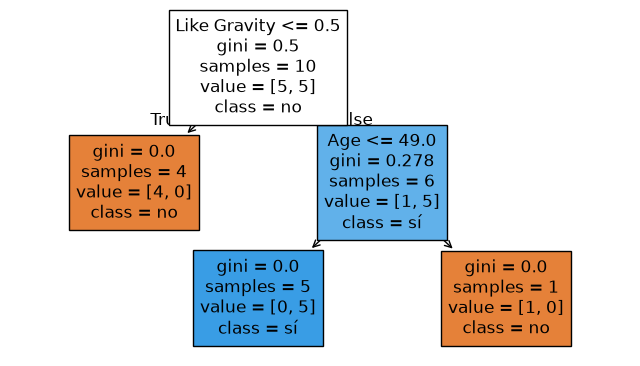

In [5]:
X = datos[["Age", "Like Dogs", "Like Gravity"]]
arbol = DecisionTreeClassifier(criterion="gini", random_state=0).fit(X, datos["Astronaut"])
print(export_text(arbol, feature_names=list(X.columns)))
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_tree(arbol, feature_names=list(X.columns), class_names=["no", "sí"], filled=True, impurity=True, ax=ax)
plt.show()

scikit-learn encuentra el mismo árbol: *Like Gravity* en la raíz y *Age ≤ 49* en el segundo nivel (scikit-learn
escribe "≤ 49.0", que en estos datos es la misma partición que "< 49"), con tres hojas puras.

## Resumen

| Dónde | Solución propuesta | Valor correcto | ¿Cambia el árbol? |
|---|---|---|---|
| Raíz, Like Dogs | 4/1 y 0/5, Gini 0.32 | 3/2 y 2/3, Gini 0.48 | No (Like Gravity sigue siendo la mejor) |
| Raíz, umbral 49 | 4/5 y 1/0 | 5/4 y 0/1 (mismo Gini 0.44) | No |
| Raíz, umbral 43 | peso $\frac8{10}$ en el segundo grupo | peso $\frac5{10}$ (resultado 0.48 bien) | No |
| Raíz, umbrales 36 y 47 | se incluyen | sobran (valores repetidos) | No |
| Segundo nivel, umbral 49 | 4/1 y 1/0, Gini 0.26 | 5/0 y 0/1, **Gini 0** | **Sí** |
| Segundo nivel, Like Dogs | 4/0 y 1/1, Gini 0.17 | 3/1 y 2/0, Gini 0.25 | **Sí** |
| Árbol final | Like Gravity → Like Dogs → Age < 45.5 (8 de 10 aciertos) | Like Gravity → Age < 49 (10 de 10) | — |

(Conteos escritos como sí/no del grupo 1 y del grupo 2.) El error que decide el árbol está en el **segundo nivel**:
los conteos del umbral 49 y de *Like Dogs*. Los errores del primer nivel son reales, pero no cambian la elección de la
raíz.